<a href="https://colab.research.google.com/github/PPGCA-MLG/2026S2/blob/main/Aula_08/1TF_ImageClassifier_VGG16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Classificação de Imagens com VGG16 e Transfer Learning**

Neste notebook, aplicamos **Transfer Learning** com a arquitetura **VGG16** para classificar **5 espécies de flores** a partir de um modelo já pré-treinado.

* **Arquitetura VGG16**
Desenvolvida pelo *Visual Geometry Group* (Oxford), a **VGG16** é uma CNN profunda com 16 camadas treináveis, baseada em blocos sequenciais de convoluções $3\times3$ e *Max Pooling*. Essa estrutura extrai padrões visuais de forma hierárquica:
    - **Camadas iniciais:** detectam bordas, cores e texturas simples.
    - **Camadas profundas:** combinam esses padrões em formas complexas e partes de objetos.

Treinar uma rede profunda do zero (_from scratch_) exigiria milhões de imagens e alto custo computacional. Em vez disso, reaproveitamos os pesos da VGG16 treinados no **ImageNet** (mais de 14 milhões de imagens):

* Já que treinar uma rede do zero (_from scratch_) exigiria milhões de imagens e alto poder computacional. Neste exemplo, usamos o *transfer learning* e aproveitamos os pesos da VGG16 já pré-treinados na base **ImageNet** (que possui mais de 14 milhões de imagens).

    1. **Base congelada (`trainable = False`):** Mantemos intactos os filtros convolucionais pré-treinados para aproveitar sua capacidade já consolidada de extrair características visuais.
    2. **Novo topo (*classifier head*):** Substituímos as camadas finais no topo (_header_) por novas camadas densas (*fully connected*) e **treinamos apenas essa parte final** para mapear as características extraídas nas nossas 5 classes de flores.

Documentação oficial: https://www.tensorflow.org/api_docs/python/tf/keras/applications/

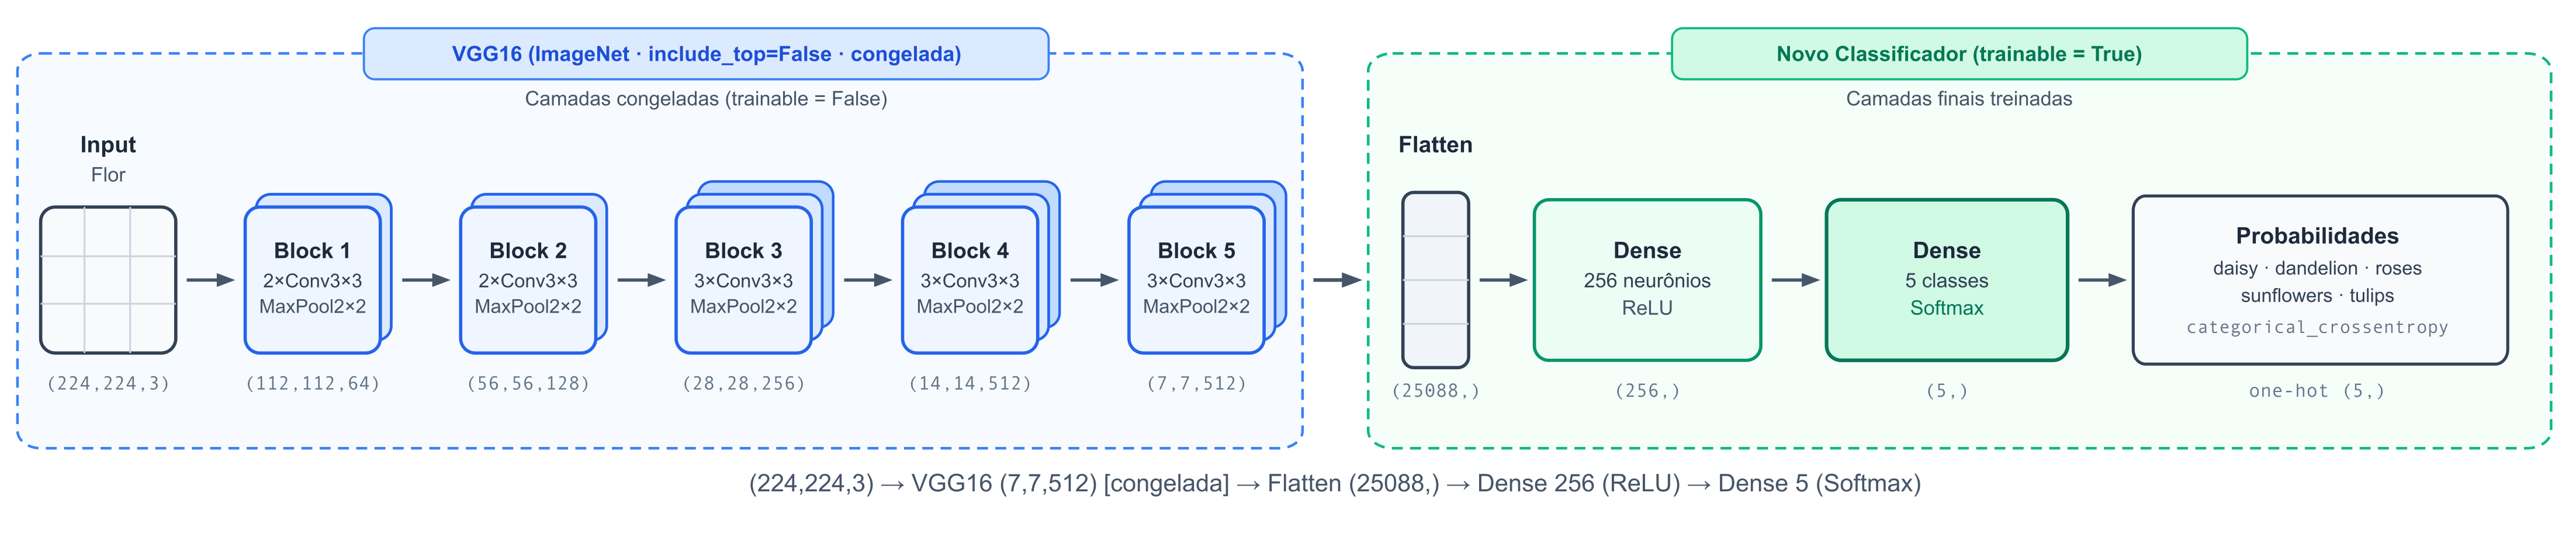

### 1. Importação das Bibliotecas e Inicialização
Nesta etapa, importamos o **TensorFlow/Keras** para construção e treinamento da rede neural, além de bibliotecas auxiliares para manipulação de diretórios (`pathlib`), cálculos numéricos (`numpy`), gráficos (`matplotlib`) e medição do tempo de execução (`time`).

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Sequential
import pathlib
import matplotlib.pyplot as plt
import numpy as np
import time

start_time = time.time()

### 2. Carregamento do Modelo Base Pré-treinado (VGG16)
Aqui carregamos a rede **VGG16** com os pesos aprendidos no dataset `imagenet`. O parâmetro `include_top=False` remove as camadas densas originais de classificação (que previam 1.000 classes), permitindo que a rede atue apenas como um **extrator de características** para imagens de entrada no formato `(224, 224, 3)`.

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

### 3. Download do Dataset e Definição de Hiperparâmetros
Fazemos o download automático do conjunto de dados público de fotos de flores (`flower_photos`) e definimos o tamanho do lote (`batch_size = 32`) que será processado a cada passo do treinamento.

In [ ]:
# Baixar e extrair o dataset de flores
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True) # por default salva em /root.keras/datasets
#data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True,cache_dir='/content') #salvar no local
data_dir = pathlib.Path(data_dir)

# Parâmetros de configuração
batch_size = 32
img_height = 180
img_width = 180

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


### 4. Preparação, Divisão e Otimização dos Dados
Carregamos as imagens diretamente das pastas, dividindo-as em **80% para treinamento** e **20% para validação**. As imagens são redimensionadas para `224x224` (exigência da VGG16) e os rótulos são codificados em formato *one-hot* (`categorical`). Por fim, aplicamos `.cache()`, `.shuffle()` e `.prefetch()` para acelerar a leitura dos dados durante o treino.

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
  '/root/.keras/datasets/flower_photos/flower_photos',
  labels='inferred',  # Automatically infer labels from subdirectory names
  label_mode='categorical', # Use categorical labels (one-hot encoded)
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(224, 224), # resize for VGG16
  batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
  '/root/.keras/datasets/flower_photos/flower_photos',
  labels='inferred',  # Automatically infer labels from subdirectory names
  label_mode='categorical', # Use categorical labels (one-hot encoded)
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(224, 224), # resize for VGG16
  batch_size=batch_size)

# Verificar o formato dos dados para diagnóstico
for images, labels in train_ds.take(1):
    print("Imagens shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Exemplo de labels:", labels[:5].numpy())

# Obter os nomes das classes
class_names = train_ds.class_names
print("Nomes das classes:", class_names)
num_classes = len(class_names)

# Otimizar o desempenho do dataset
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Imagens shape: (32, 224, 224, 3)
Labels shape: (32, 5)
Exemplo de labels: [[0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0.]]
Nomes das classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


### 5. Congelamento (*Freezing*) das Camadas da Rede Base
Definimos `layer.trainable = False` em todas as camadas do `base_model`. Isso impede que os pesos pré-treinados da VGG16 sejam alterados durante o treinamento, evitando a perda do conhecimento visual já adquirido e reduzindo drasticamente o custo computacional.

In [ ]:
for layer in base_model.layers:
    layer.trainable = False

### 6. Construção do Novo Classificador (Topo da Rede)
Acoplamos novas camadas treináveis sobre a base congelada da VGG16:
1. **`Flatten()`:** Transforma o mapa de características tridimensional `(7, 7, 512)` em um vetor unidimensional.
2. **`Dense(256, activation='relu')`:** Camada oculta que combina as características extraídas para aprender padrões específicos das flores.
3. **`Dense(num_classes, activation='softmax')`:** Camada de saída que gera a probabilidade de a imagem pertencer a cada uma das 5 classes.

In [ ]:
model = models.Sequential()
model.add(base_model)
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(num_classes, activation='softmax'))


### 7. Compilação do Modelo
Configuramos o processo de aprendizado escolhendo o otimizador **Adam**, a função de perda **Categorical Crossentropy** (adequada para classificação multiclasse *one-hot*) e a métrica de **Acurácia**.

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

### 8. Resumo da Arquitetura e Treinamento
Exibimos o resumo do modelo (`model.summary()`), onde é possível notar que os ~14,7 milhões de parâmetros da VGG16 aparecem como *Non-trainable* (congelados), enquanto apenas os ~6,4 milhões de parâmetros das camadas densas finais serão treinados ao longo de **10 épocas**.

In [ ]:
model.summary()

# Treinar o modelo
epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,138,757 (80.64 MB)

 Trainable params: 6,424,069 (24.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 74s 540ms/step - accuracy: 0.7023 - loss: 5.0340 - val_accuracy: 0.7289 - val_loss: 0.8710
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 175ms/step - accuracy: 0.8798 - loss: 0.3924 - val_accuracy: 0.7888 - val_loss: 0.9088
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 178ms/step - accuracy: 0.9438 - loss: 0.1727 - val_accuracy: 0.8106 - val_loss: 1.0655
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 181ms/step - accuracy: 0.9700 - loss: 0.1019 - val_accuracy: 0.8120 - val_loss: 1.1870
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 185ms/step - accuracy: 0.9796 - loss: 0.0887 - val_accuracy: 0.8134 - val_loss: 1.2919
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 187ms/step - accuracy: 0.9881 - loss: 0.0407 - val_accuracy: 0.8174 - val_loss: 1.2271
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 189ms/step - accuracy: 0.9935 - loss: 0.0216 - val_accuracy: 0.8229 - val_loss: 1.1900
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 189ms/step - accuracy: 0.9966 - loss: 0.0105 - val_accu

### 9. Avaliação, Visualização das Previsões e Exportação do Modelo
Por fim, plotamos as curvas de **acurácia e perda (*loss*)** para diagnosticar o comportamento do aprendizado (observando a convergência e eventuais sinais de *overfitting*), avaliamos o desempenho final no conjunto de validação, visualizamos exemplos práticos de previsões com suas probabilidades e salvamos o modelo treinado em disco (`.h5`).

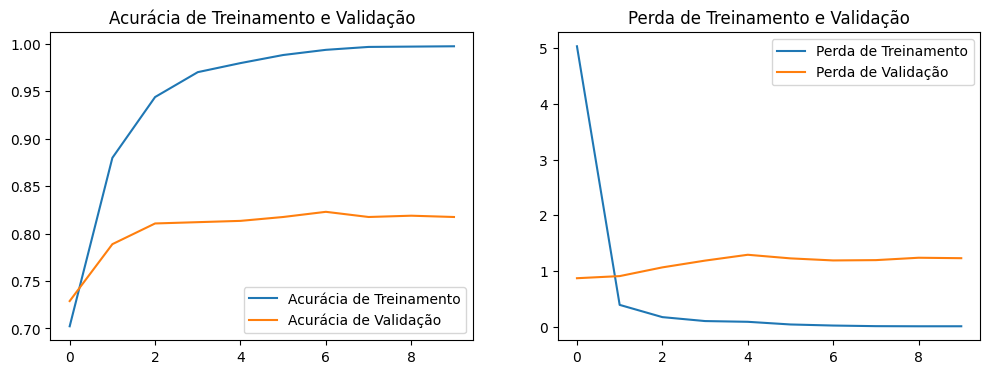

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - accuracy: 0.8174 - loss: 1.2303
Acurácia no conjunto de validação: 0.8174
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


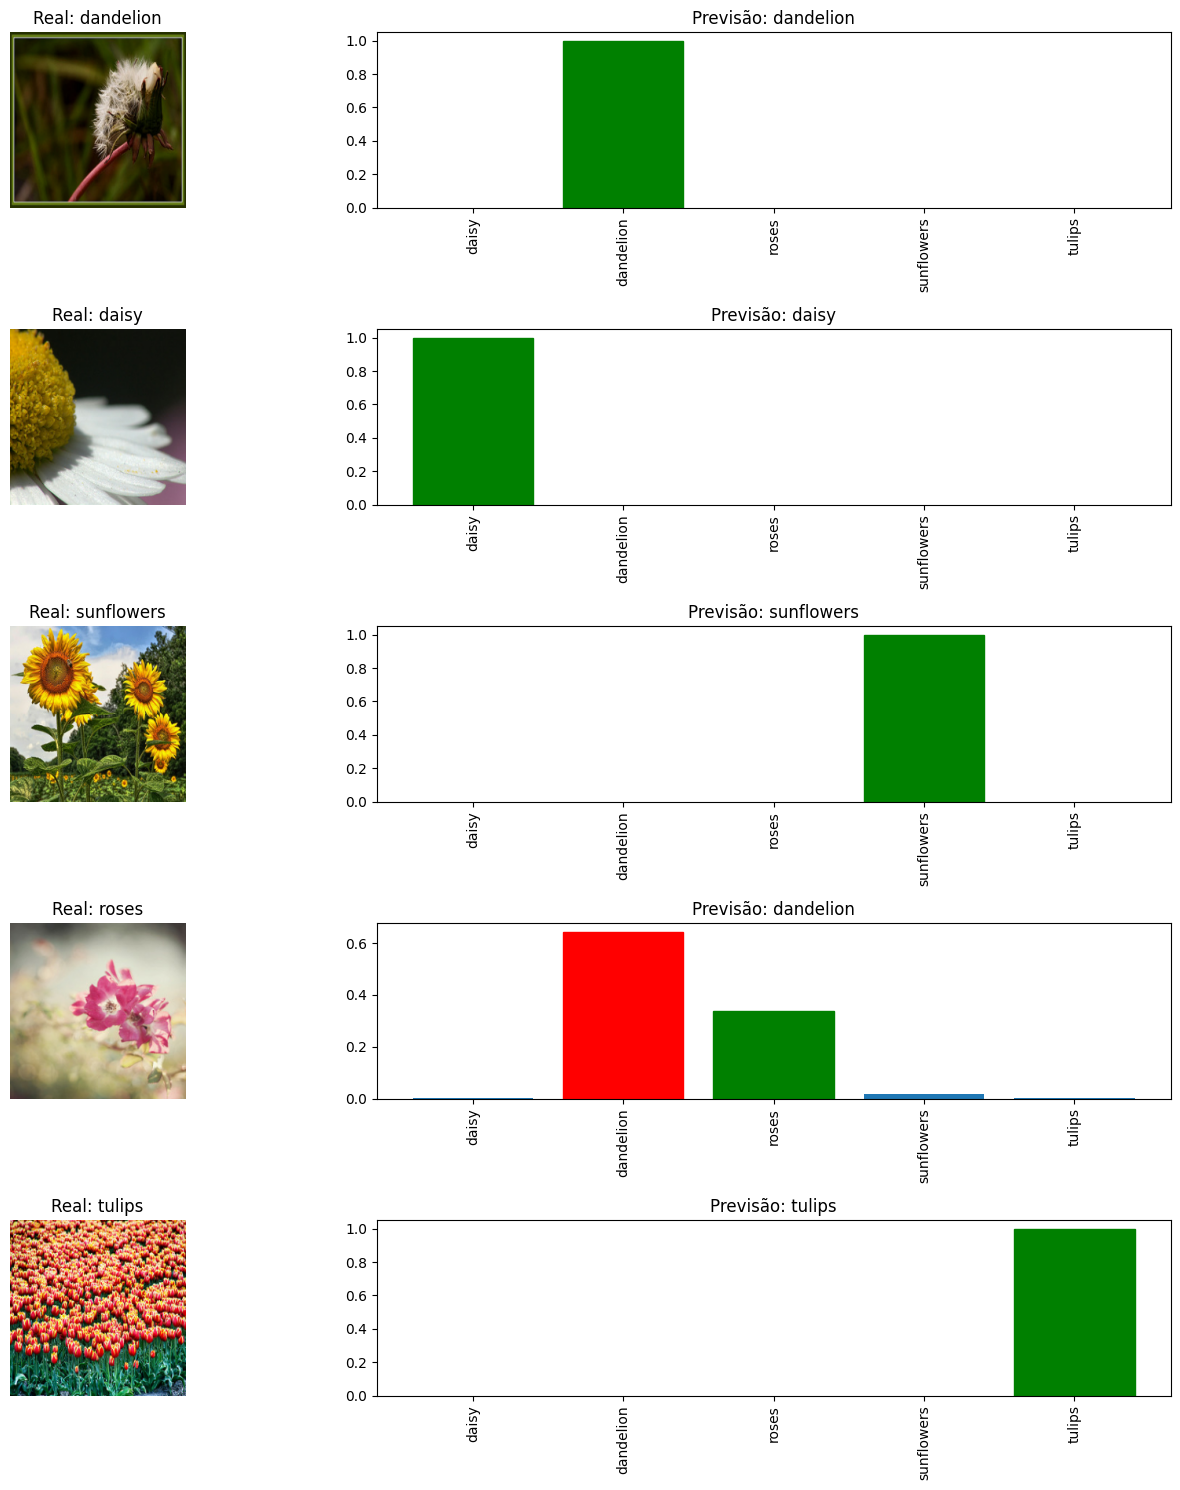

Modelo salvo como 'flower_classifier_categorical.h5'


In [ ]:
# Plotar a acurácia e perda durante o treinamento
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Acurácia de Treinamento')
plt.plot(epochs_range, val_acc, label='Acurácia de Validação')
plt.legend(loc='lower right')
plt.title('Acurácia de Treinamento e Validação')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Perda de Treinamento')
plt.plot(epochs_range, val_loss, label='Perda de Validação')
plt.legend(loc='upper right')
plt.title('Perda de Treinamento e Validação')
plt.show()

# Avaliar o modelo
evaluation = model.evaluate(val_ds)
print(f"Acurácia no conjunto de validação: {evaluation[1]:.4f}")

# Função para fazer previsões e visualizá-las
def visualize_predictions(model, dataset, class_names, num_images=5):
    plt.figure(figsize=(15, 3*num_images))

    i = 0
    for images, labels in dataset.take(1):
        for j in range(min(num_images, len(images))):
            # Fazer a previsão
            img = tf.expand_dims(images[j], 0)
            predictions = model.predict(img)
            predicted_class = np.argmax(predictions[0])
            actual_class = np.argmax(labels[j])

            # Plotar a imagem
            plt.subplot(num_images, 2, i*2 + 1)
            plt.imshow(images[j].numpy().astype('uint8'))
            plt.title(f"Real: {class_names[actual_class]}")
            plt.axis('off')

            # Plotar as probabilidades
            plt.subplot(num_images, 2, i*2 + 2)
            barlist = plt.bar(range(len(class_names)), predictions[0])
            barlist[predicted_class].set_color('red')
            barlist[actual_class].set_color('green')
            plt.xticks(range(len(class_names)), class_names, rotation=90)
            plt.title(f"Previsão: {class_names[predicted_class]}")

            i += 1
            if i >= num_images:
                break

    plt.tight_layout()
    plt.show()

# Visualizar algumas previsões
visualize_predictions(model, val_ds, class_names)

# Salvar o modelo
model.save('flower_classifier_categorical.h5')
print("Modelo salvo como 'flower_classifier_categorical.h5'")

In [ ]:
end_time = time.time()

elapsed_time = end_time - start_time
print(f"Training time: {elapsed_time:.2f} seconds")

Training time: 249.77 seconds
